# Episode models — unusual vs profitable (Phase 2)

Uses the cached econ/finance episode table from [`episode_eda.ipynb`](episode_eda.ipynb).

**Question:** Are statistically unusual buy episodes (Isolation Forest) the same ones whose features predict high excess return (polynomial / ridge regression)?

**Methods**
1. PCA on the eight training features → keep **k** for ~90% variance
2. Isolation Forest on **raw features** and on **PC scores** (no excess return in the fit)
3. Linear + ridge degree-2 polynomial regression of excess return on raw features and on PCs
4. On held-out markets: top 1% by each ranking → overlaps and mean realized excess return

**Split:** fit on markets that resolved earlier; score markets that resolved later.


## 0. Load episodes and prepare features


In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
from IPython.display import display

FEATURE_COLS = [
    "size_vs_self", "size_vs_market", "lead_time_hours", "same_event_share",
    "entry_price", "log_unique_markets", "account_age_hours", "concentration",
]
OUT = Path("data/episodes")
ep = pd.read_parquet(OUT / "episodes.parquet")
assert not ep["is_bot"].any(), "episodes.parquet should already exclude bots"
ep["resolved_at"] = pd.to_datetime(ep["resolved_at"], utc=True)
print(f"loaded {len(ep):,} episodes | {ep['market'].nunique():,} markets | {ep['wallet'].nunique():,} wallets")
display(ep[FEATURE_COLS + ["excess_return"]].describe().T)


loaded 46,984 episodes | 1,436 markets | 22,344 wallets


,count,mean,std,min,25%,50%,75%,max
size_vs_self,46984.0,2.446288,26.689059,5.944414e-06,0.950610,1.000000,1.000001,3676.416292
size_vs_market,46984.0,0.152424,3.230227,1.163828e-08,0.000047,0.002053,0.029477,636.041928
lead_time_hours,46984.0,60.342273,192.335334,-6.948442e+02,-12.173958,43.310000,152.998056,743.152500
same_event_share,46984.0,0.503140,0.429649,1.241305e-06,0.058609,0.400000,1.000000,1.000000
entry_price,46984.0,0.550425,0.340968,1.000000e-03,0.218151,0.540000,0.884071,0.999000
log_unique_markets,46984.0,2.224900,1.606178,6.931472e-01,0.693147,1.609438,3.091042,6.210600
account_age_hours,46984.0,131.190922,197.982560,0.000000e+00,0.000000,2.902500,208.493958,826.936389
concentration,46984.0,0.502279,0.377826,9.668029e-03,0.131579,0.421150,1.000000,1.000000
excess_return,46984.0,-0.034867,0.311918,-9.980000e-01,-0.210000,0.001000,0.122278,0.991024


## 1. Temporal split by market `resolved_at`

70% earliest-resolving markets → train; rest → test. No market on both sides.


In [2]:
mres = ep.groupby("market")["resolved_at"].min().sort_values()
cut = int(0.7 * len(mres))
train_markets = set(mres.index[:cut])
test_markets = set(mres.index[cut:])
train = ep[ep["market"].isin(train_markets)].copy()
test = ep[ep["market"].isin(test_markets)].copy()
assert len(set(train["market"]) & set(test["market"])) == 0
print(f"train: {len(train_markets):,} markets, {len(train):,} episodes, mean ER={train['excess_return'].mean():.4f}")
print(f"test:  {len(test_markets):,} markets, {len(test):,} episodes, mean ER={test['excess_return'].mean():.4f}")
print("train window:", train["resolved_at"].min(), "→", train["resolved_at"].max())
print("test  window:", test["resolved_at"].min(), "→", test["resolved_at"].max())


train: 1,005 markets, 38,862 episodes, mean ER=-0.0425
test:  431 markets, 8,122 episodes, mean ER=0.0017
train window: 2026-09-01 12:50:31+00:00 → 2026-09-30 20:53:44+00:00
test  window: 2026-09-30 21:44:59+00:00 → 2026-10-27 01:13:39.943634+00:00


## 2. Transform features (log ratios / age / lead time, then standardize)

Fit the scaler on **train only**. Excess return is never scaled into X.


In [3]:
def transform_features(df):
    Z = df[FEATURE_COLS].copy()
    Z["size_vs_self"] = np.log1p(Z["size_vs_self"].clip(lower=0))
    Z["size_vs_market"] = np.log1p(Z["size_vs_market"].clip(lower=0))
    Z["lead_time_hours"] = np.arcsinh(Z["lead_time_hours"])
    Z["account_age_hours"] = np.log1p(Z["account_age_hours"].clip(lower=0))
    return Z

Xtr_raw = transform_features(train)
Xte_raw = transform_features(test)
ytr = train["excess_return"].to_numpy()
yte = test["excess_return"].to_numpy()

scaler = StandardScaler().fit(Xtr_raw)
Xtr = scaler.transform(Xtr_raw)
Xte = scaler.transform(Xte_raw)
print("X train", Xtr.shape, "| X test", Xte.shape)
print("label withheld from IF: excess_return")


X train (38862, 8) | X test (8122, 8)
label withheld from IF: excess_return


## 3. PCA — choose k for ~90% variance (train only)


variance ratios: [0.442 0.147 0.131 0.1   0.095 0.044 0.025 0.016]
cumulative:      [0.442 0.589 0.721 0.821 0.916 0.96  0.984 1.   ]
k for ≥90% variance: 5


,PC1,PC2,PC3,PC4,PC5
size_vs_self,0.056,0.682,0.350,-0.483,0.404
size_vs_market,0.234,0.429,-0.001,0.829,0.216
lead_time_hours,-0.056,-0.102,0.896,0.165,-0.372
same_event_share,-0.488,0.175,-0.060,0.021,0.068
entry_price,0.206,0.504,-0.246,-0.118,-0.790
log_unique_markets,0.484,-0.015,0.040,0.005,0.110
account_age_hours,0.437,-0.167,-0.026,-0.161,0.104
concentration,-0.483,0.170,-0.093,0.114,-0.007


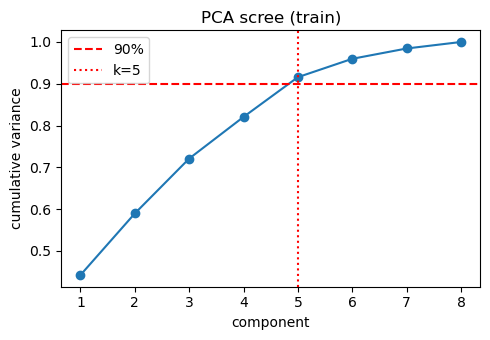

In [4]:
pca_full = PCA().fit(Xtr)
cum = np.cumsum(pca_full.explained_variance_ratio_)
k = int(np.searchsorted(cum, 0.90) + 1)
k = max(k, 1)
print("variance ratios:", np.round(pca_full.explained_variance_ratio_, 3))
print("cumulative:     ", np.round(cum, 3))
print(f"k for ≥90% variance: {k}")

pca = PCA(n_components=k).fit(Xtr)
Xtr_pc = pca.transform(Xtr)
Xte_pc = pca.transform(Xte)

loadings = pd.DataFrame(
    pca.components_.T,
    index=FEATURE_COLS,
    columns=[f"PC{i+1}" for i in range(k)],
)
display(loadings.round(3))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(range(1, len(cum) + 1), cum, marker="o")
ax.axhline(0.9, color="red", ls="--", label="90%")
ax.axvline(k, color="red", ls=":", label=f"k={k}")
ax.set_xlabel("component"); ax.set_ylabel("cumulative variance"); ax.legend()
ax.set_title("PCA scree (train)")
plt.tight_layout(); plt.show()


## 4. Isolation Forest — raw features vs PCA scores

Unsupervised: **excess return is not used**. Rank test episodes by anomaly score (higher = more unusual). Top 1% = unusual set.


test n=8,122 | top 1% size = 82
IF raw: mean ER in top 1% = 0.022233711766682276
IF PCA: mean ER in top 1% = 0.007742850379363082
all test mean ER = 0.0016740563193186927


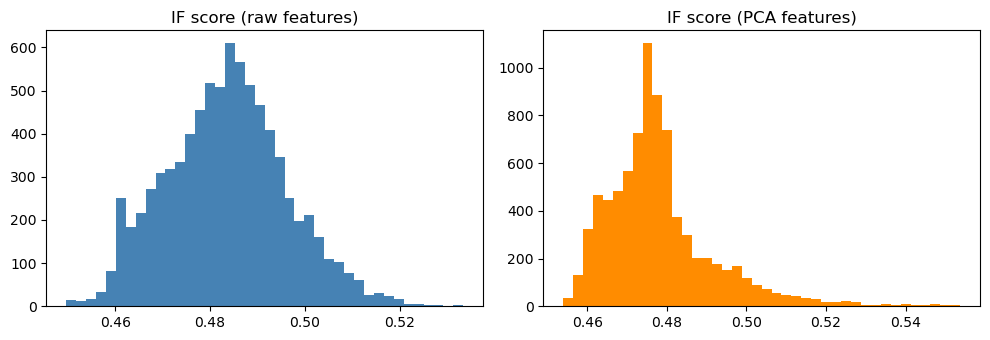

In [5]:
def iforest_scores(X_fit, X_score, random_state=42):
    """Fit IF on X_fit; return anomaly scores for X_score (higher = more anomalous)."""
    clf = IsolationForest(
        n_estimators=200,
        contamination=0.05,  # unused for ranking; kept for sklearn API parity with course demo
        random_state=random_state,
        n_jobs=-1,
    )
    clf.fit(X_fit)
    # decision_function: higher = more normal; flip so higher = more unusual
    raw = -clf.decision_function(X_score)
    # 0-1-ish logistic transform (same spirit as insider_demo)
    score = 1.0 / (1.0 + np.exp(-raw))
    return score, clf

if_raw_score, if_raw_model = iforest_scores(Xtr, Xte)
if_pca_score, if_pca_model = iforest_scores(Xtr_pc, Xte_pc)

test = test.copy()
test["if_raw_score"] = if_raw_score
test["if_pca_score"] = if_pca_score
test["if_raw_rank"] = test["if_raw_score"].rank(ascending=False, method="first").astype(int)
test["if_pca_rank"] = test["if_pca_score"].rank(ascending=False, method="first").astype(int)

n_top = max(1, int(np.ceil(0.01 * len(test))))
print(f"test n={len(test):,} | top 1% size = {n_top}")
print("IF raw: mean ER in top 1% =", test.nsmallest(n_top, "if_raw_rank")["excess_return"].mean())
print("IF PCA: mean ER in top 1% =", test.nsmallest(n_top, "if_pca_rank")["excess_return"].mean())
print("all test mean ER =", test["excess_return"].mean())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(test["if_raw_score"], bins=40, color="steelblue", edgecolor="none")
ax[0].set_title("IF score (raw features)")
ax[1].hist(test["if_pca_score"], bins=40, color="darkorange", edgecolor="none")
ax[1].set_title("IF score (PCA features)")
plt.tight_layout(); plt.show()


## 5. Polynomial regression of excess return

Linear and ridge-penalized degree-2, on raw features and on PC scores. Ridge α chosen by CV on **training rows** (GroupKFold by market would be ideal; here we use RidgeCV on train, then report test RMSE).


In [6]:
from sklearn.model_selection import GroupKFold

def poly_fit_predict(X_train, y_train, X_test, groups_train, degree=2, ridge=True):
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    if ridge:
        # CV over markets via GroupKFold
        alphas = np.logspace(-3, 3, 13)
        best_alpha, best_rmse = None, np.inf
        gkf = GroupKFold(n_splits=min(5, len(np.unique(groups_train))))
        for a in alphas:
            rmses = []
            for tr_i, va_i in gkf.split(X_train, y_train, groups_train):
                pipe = Pipeline([
                    ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
                    ("ridge", RidgeCV(alphas=[a])),  # single alpha
                ])
                # simpler: Ridge with fixed alpha
                from sklearn.linear_model import Ridge
                pipe = Pipeline([
                    ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
                    ("ridge", Ridge(alpha=a)),
                ])
                pipe.fit(X_train[tr_i], y_train[tr_i])
                pred = pipe.predict(X_train[va_i])
                rmses.append(mean_squared_error(y_train[va_i], pred, squared=False))
            m = float(np.mean(rmses))
            if m < best_rmse:
                best_rmse, best_alpha = m, a
        model = Pipeline([
            ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
            ("ridge", Ridge(alpha=best_alpha)),
        ])
        model.fit(X_train, y_train)
        return model, model.predict(X_test), best_alpha, best_rmse
    else:
        model = Pipeline([
            ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
            ("lr", LinearRegression()),
        ])
        model.fit(X_train, y_train)
        return model, model.predict(X_test), None, None

groups_train = train["market"].to_numpy()

models = {}
preds = {}
rows_rmse = []
for name, Xa, Xb in [
    ("lin_raw", Xtr, Xte),
    ("lin_pca", Xtr_pc, Xte_pc),
    ("ridge_raw", Xtr, Xte),
    ("ridge_pca", Xtr_pc, Xte_pc),
]:
    ridge = name.startswith("ridge")
    model, pred, alpha, cv_rmse = poly_fit_predict(
        Xa, ytr, Xb, groups_train, degree=2, ridge=ridge,
    )
    models[name] = model
    preds[name] = pred
    rmse = mean_squared_error(yte, pred, squared=False)
    rows_rmse.append({"model": name, "alpha": alpha, "cv_rmse_train": cv_rmse, "test_rmse": rmse})
    test[f"pred_{name}"] = pred
    test[f"rank_{name}"] = pd.Series(pred, index=test.index).rank(ascending=False, method="first").astype(int)

rmse_tbl = pd.DataFrame(rows_rmse)
display(rmse_tbl)
print("baseline RMSE (predict train mean):", mean_squared_error(yte, np.full_like(yte, ytr.mean()), squared=False))


,model,alpha,cv_rmse_train,test_rmse
0,lin_raw,NaN,NaN,0.314855
1,lin_pca,NaN,NaN,0.314576
2,ridge_raw,1000.0,0.316047,0.313639
3,ridge_pca,1000.0,0.317410,0.313933


baseline RMSE (predict train mean): 0.3144814477403204


## 6. Result table — top 1% lists: overlap and mean excess return


In [7]:
n_top = max(1, int(np.ceil(0.01 * len(test))))
base_er = test["excess_return"].mean()

rank_cols = {
    "IF_raw": "if_raw_rank",
    "IF_pca": "if_pca_rank",
    "lin_raw": "rank_lin_raw",
    "lin_pca": "rank_lin_pca",
    "ridge_raw": "rank_ridge_raw",
    "ridge_pca": "rank_ridge_pca",
}

def top_index(rank_col):
    return set(test.nsmallest(n_top, rank_col).index)

tops = {name: top_index(col) for name, col in rank_cols.items()}

# summary: size, mean ER, lift vs all-test
summary = []
for name, idx in tops.items():
    er = test.loc[list(idx), "excess_return"]
    summary.append({
        "list": name,
        "n": len(idx),
        "mean_excess_return": er.mean(),
        "all_test_mean_ER": base_er,
        "lift_vs_all": er.mean() - base_er,
    })
summary_df = pd.DataFrame(summary).sort_values("mean_excess_return", ascending=False)
display(summary_df)

# pairwise overlap (Jaccard and count)
names = list(tops)
overlap_n = pd.DataFrame(index=names, columns=names, dtype=float)
overlap_j = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        inter = len(tops[a] & tops[b])
        union = len(tops[a] | tops[b])
        overlap_n.loc[a, b] = inter
        overlap_j.loc[a, b] = inter / union if union else 0.0

print(f"\nTop 1% size = {n_top}. Pairwise overlap counts:")
display(overlap_n.astype(int))
print("Jaccard overlap:")
display(overlap_j.round(3))

# focus: IF vs best ridge predictions
print("\nIF_raw ∩ ridge_raw:", len(tops["IF_raw"] & tops["ridge_raw"]), "/", n_top)
print("IF_pca ∩ ridge_pca:", len(tops["IF_pca"] & tops["ridge_pca"]), "/", n_top)
print("IF_raw ∩ IF_pca:", len(tops["IF_raw"] & tops["IF_pca"]), "/", n_top)
print("ridge_raw ∩ ridge_pca:", len(tops["ridge_raw"] & tops["ridge_pca"]), "/", n_top)


,list,n,mean_excess_return,all_test_mean_ER,lift_vs_all
0,IF_raw,82,0.022234,0.001674,0.020560
1,IF_pca,82,0.007743,0.001674,0.006069
3,lin_pca,82,0.003731,0.001674,0.002057
2,lin_raw,82,0.001343,0.001674,-0.000332
4,ridge_raw,82,0.000790,0.001674,-0.000884
5,ridge_pca,82,-0.003664,0.001674,-0.005338



Top 1% size = 82. Pairwise overlap counts:


,IF_raw,IF_pca,lin_raw,lin_pca,ridge_raw,ridge_pca
IF_raw,82,36,3,8,3,8
IF_pca,36,82,10,16,10,16
lin_raw,3,10,82,30,71,29
lin_pca,8,16,30,82,31,72
ridge_raw,3,10,71,31,82,30
ridge_pca,8,16,29,72,30,82


Jaccard overlap:


,IF_raw,IF_pca,lin_raw,lin_pca,ridge_raw,ridge_pca
IF_raw,1.000,0.281,0.019,0.051,0.019,0.051
IF_pca,0.281,1.000,0.065,0.108,0.065,0.108
lin_raw,0.019,0.065,1.000,0.224,0.763,0.215
lin_pca,0.051,0.108,0.224,1.000,0.233,0.783
ridge_raw,0.019,0.065,0.763,0.233,1.000,0.224
ridge_pca,0.051,0.108,0.215,0.783,0.224,1.000



IF_raw ∩ ridge_raw: 3 / 82
IF_pca ∩ ridge_pca: 16 / 82
IF_raw ∩ IF_pca: 36 / 82
ridge_raw ∩ ridge_pca: 30 / 82


## 6b. Overlap: largest predicted excess returns vs IF-unusual

For each cutoff (top 1%, 5%, 10% of the **test** set):

- **Unusual** = highest Isolation Forest anomaly scores (raw features, and separately PCA)
- **Largest predicted ER** = highest ridge degree-2 predictions (raw features, and separately PCA)

Report: size of each set, **intersection size**, Jaccard, and mean **realized** excess return in four buckets: both / IF-only / pred-only / neither.


=== Overlap of IF-unusual vs largest predicted excess return ===


,comparison,top_pct,n_each,intersection,union,jaccard,pct_of_unusual_also_high_pred,pct_of_high_pred_also_unusual,mean_ER_both,mean_ER_IF_only,mean_ER_pred_only,mean_ER_neither,mean_ER_all_test
0,IF_raw vs ridge_raw,1,82,3,161,0.0186,3.6585,3.6585,0.0607,0.0208,-0.0015,0.0015,0.0017
1,IF_raw vs ridge_raw,5,407,38,776,0.0490,9.3366,9.3366,-0.0404,0.0077,0.0180,0.0008,0.0017
2,IF_raw vs ridge_raw,10,813,91,1535,0.0593,11.1931,11.1931,0.0202,0.0102,0.0334,-0.0030,0.0017
3,IF_pca vs ridge_pca,1,82,16,148,0.1081,19.5122,19.5122,-0.0978,0.0333,0.0191,0.0015,0.0017
4,IF_pca vs ridge_pca,5,407,76,738,0.1030,18.6732,18.6732,-0.0104,-0.0029,0.0156,0.0014,0.0017
5,IF_pca vs ridge_pca,10,813,111,1515,0.0733,13.6531,13.6531,-0.0006,-0.0004,0.0246,-0.0005,0.0017
6,IF_raw vs lin_raw,1,82,3,161,0.0186,3.6585,3.6585,0.0607,0.0208,-0.0009,0.0015,0.0017
7,IF_raw vs lin_raw,5,407,39,775,0.0503,9.5823,9.5823,-0.0313,0.0069,0.0193,0.0007,0.0017
8,IF_raw vs lin_raw,10,813,93,1533,0.0607,11.4391,11.4391,0.0353,0.0082,0.0311,-0.0027,0.0017
9,IF_pca vs lin_pca,1,82,16,148,0.1081,19.5122,19.5122,-0.0978,0.0333,0.0283,0.0014,0.0017



Headline (IF raw vs ridge raw, top 1%): 3/82 episodes in both (3.7% of unusual also high-pred; Jaccard=0.019).

=== Mean realized ER by overlap bucket ===


bucket                        IF_only      both   neither  pred_only
comparison          top_pct                                         
IF_pca vs lin_pca   1        0.033321 -0.097768  0.001391   0.028337
                    5       -0.002503 -0.012060  0.001333   0.016775
                    10      -0.000338 -0.000883 -0.000544   0.024929
IF_pca vs ridge_pca 1        0.033321 -0.097768  0.001467   0.019149
                    5       -0.002942 -0.010401  0.001379   0.015650
                    10      -0.000385 -0.000582 -0.000506   0.024609
IF_raw vs lin_raw   1        0.020772  0.060737  0.001488  -0.000913
                    5        0.006899 -0.031307  0.000706   0.019265
                    10       0.008218  0.035256 -0.002731   0.031107
IF_raw vs ridge_raw 1        0.020772  0.060737  0.001494  -0.001486
                    5        0.007728 -0.040361  0.000767   0.017999
                    10       0.010188  0.020220 -0.002992   0.033393

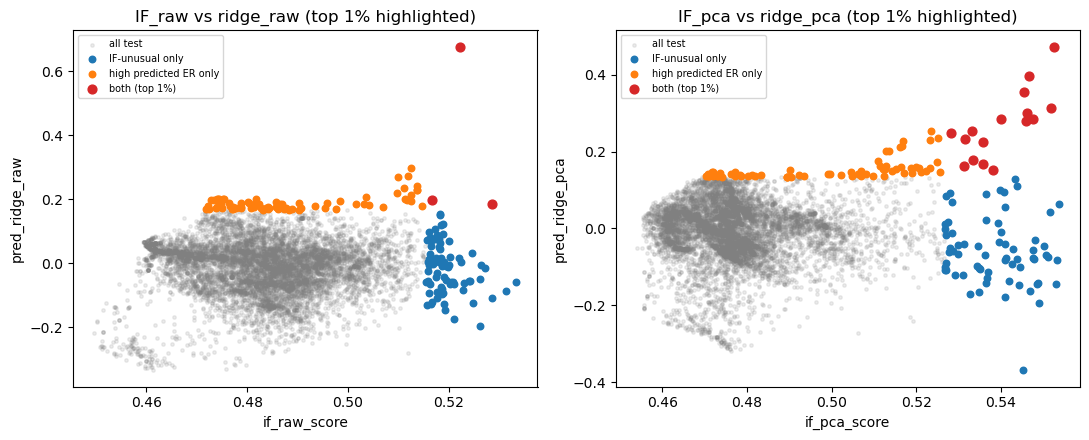

wrote data/episodes/if_vs_pred_overlap.csv
wrote data/episodes/if_vs_pred_buckets.csv


In [8]:

def top_frac(series, frac, higher_is_more_extreme=True):
    n = max(1, int(np.ceil(frac * len(series))))
    if higher_is_more_extreme:
        return set(series.nlargest(n).index)
    return set(series.nsmallest(n).index)

pairs = [
    ("IF_raw vs ridge_raw", "if_raw_score", "pred_ridge_raw"),
    ("IF_pca vs ridge_pca", "if_pca_score", "pred_ridge_pca"),
    ("IF_raw vs lin_raw", "if_raw_score", "pred_lin_raw"),
    ("IF_pca vs lin_pca", "if_pca_score", "pred_lin_pca"),
]
fracs = [0.01, 0.05, 0.10]

overlap_rows = []
bucket_rows = []

for pair_name, if_col, pred_col in pairs:
    for frac in fracs:
        unusual = top_frac(test[if_col], frac, True)
        high_pred = top_frac(test[pred_col], frac, True)
        both = unusual & high_pred
        if_only = unusual - high_pred
        pred_only = high_pred - unusual
        neither = set(test.index) - unusual - high_pred
        n = max(1, int(np.ceil(frac * len(test))))
        jacc = len(both) / len(unusual | high_pred) if (unusual | high_pred) else 0.0
        overlap_rows.append({
            "comparison": pair_name,
            "top_pct": int(frac * 100),
            "n_each": n,
            "intersection": len(both),
            "union": len(unusual | high_pred),
            "jaccard": jacc,
            "pct_of_unusual_also_high_pred": 100 * len(both) / len(unusual) if unusual else 0.0,
            "pct_of_high_pred_also_unusual": 100 * len(both) / len(high_pred) if high_pred else 0.0,
            "mean_ER_both": test.loc[list(both), "excess_return"].mean() if both else np.nan,
            "mean_ER_IF_only": test.loc[list(if_only), "excess_return"].mean() if if_only else np.nan,
            "mean_ER_pred_only": test.loc[list(pred_only), "excess_return"].mean() if pred_only else np.nan,
            "mean_ER_neither": test.loc[list(neither), "excess_return"].mean() if neither else np.nan,
            "mean_ER_all_test": test["excess_return"].mean(),
        })
        for label, idx in [
            ("both", both), ("IF_only", if_only), ("pred_only", pred_only), ("neither", neither)
        ]:
            bucket_rows.append({
                "comparison": pair_name,
                "top_pct": int(frac * 100),
                "bucket": label,
                "n": len(idx),
                "mean_realized_ER": test.loc[list(idx), "excess_return"].mean() if idx else np.nan,
            })

overlap_df = pd.DataFrame(overlap_rows)
bucket_df = pd.DataFrame(bucket_rows)

print("=== Overlap of IF-unusual vs largest predicted excess return ===")
display(overlap_df.round(4))

# Highlight the main planned comparison at 1%
main = overlap_df[(overlap_df["comparison"] == "IF_raw vs ridge_raw") & (overlap_df["top_pct"] == 1)].iloc[0]
print(
    f"\nHeadline (IF raw vs ridge raw, top 1%): "
    f"{int(main['intersection'])}/{int(main['n_each'])} episodes in both "
    f"({main['pct_of_unusual_also_high_pred']:.1f}% of unusual also high-pred; "
    f"Jaccard={main['jaccard']:.3f})."
)

print("\n=== Mean realized ER by overlap bucket ===")
display(bucket_df.pivot_table(index=["comparison", "top_pct"], columns="bucket", values="mean_realized_ER"))

# Scatter: IF score vs predicted ER, mark top-1% regions
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (title, if_col, pred_col) in zip(axes, pairs[:2]):
    x = test[if_col]
    y = test[pred_col]
    ax.scatter(x, y, s=6, alpha=0.15, c="0.5", label="all test")
    u = top_frac(x, 0.01, True)
    p = top_frac(y, 0.01, True)
    ax.scatter(test.loc[list(u - p), if_col], test.loc[list(u - p), pred_col],
               s=22, c="C0", label="IF-unusual only")
    ax.scatter(test.loc[list(p - u), if_col], test.loc[list(p - u), pred_col],
               s=22, c="C1", label="high predicted ER only")
    ax.scatter(test.loc[list(u & p), if_col], test.loc[list(u & p), pred_col],
               s=40, c="C3", label="both (top 1%)")
    ax.set_xlabel(if_col)
    ax.set_ylabel(pred_col)
    ax.set_title(title + " (top 1% highlighted)")
    ax.legend(fontsize=7, loc="best")
plt.tight_layout()
plt.show()

overlap_df.to_csv(OUT / "if_vs_pred_overlap.csv", index=False)
bucket_df.to_csv(OUT / "if_vs_pred_buckets.csv", index=False)
print("wrote", OUT / "if_vs_pred_overlap.csv")
print("wrote", OUT / "if_vs_pred_buckets.csv")


## 8. Save scored test set + conclusion


In [9]:
scored_path = OUT / "test_scored.parquet"
test.to_parquet(scored_path, index=False)
summary_df.to_csv(OUT / "top1pct_summary.csv", index=False)
overlap_n.astype(int).to_csv(OUT / "top1pct_overlap_counts.csv")
print("wrote", scored_path)
print("wrote", OUT / "top1pct_summary.csv")

# Auto-draft conclusion from the numbers
if_raw_er = summary_df.loc[summary_df["list"]=="IF_raw", "mean_excess_return"].iloc[0]
if_pca_er = summary_df.loc[summary_df["list"]=="IF_pca", "mean_excess_return"].iloc[0]
ridge_raw_er = summary_df.loc[summary_df["list"]=="ridge_raw", "mean_excess_return"].iloc[0]
ridge_pca_er = summary_df.loc[summary_df["list"]=="ridge_pca", "mean_excess_return"].iloc[0]
j_if_ridge = overlap_j.loc["IF_raw", "ridge_raw"]
j_if = overlap_j.loc["IF_raw", "IF_pca"]
j_ridge = overlap_j.loc["ridge_raw", "ridge_pca"]

print("""
CONCLUSION (draft from this run)
--------------------------------
""")
print(f"All held-out episodes mean excess return = {base_er:.4f}.")
print(f"Top 1% IF (raw features) mean ER = {if_raw_er:.4f} (lift {if_raw_er-base_er:+.4f}).")
print(f"Top 1% IF (PCA)          mean ER = {if_pca_er:.4f} (lift {if_pca_er-base_er:+.4f}).")
print(f"Top 1% ridge°2 (raw)     mean ER = {ridge_raw_er:.4f} (lift {ridge_raw_er-base_er:+.4f}).")
print(f"Top 1% ridge°2 (PCA)     mean ER = {ridge_pca_er:.4f} (lift {ridge_pca_er-base_er:+.4f}).")
print(f"Jaccard(IF_raw, ridge_raw) = {j_if_ridge:.3f} — "
      f"{'largely different lists' if j_if_ridge < 0.2 else 'moderate overlap' if j_if_ridge < 0.5 else 'substantial overlap'}.")
print(f"Jaccard(IF_raw, IF_pca) = {j_if:.3f} — PCA {'changed' if j_if < 0.8 else 'barely changed'} the unusual ranking.")
print(f"Jaccard(ridge_raw, ridge_pca) = {j_ridge:.3f} — PCA {'changed' if j_ridge < 0.8 else 'barely changed'} the predicted-profit ranking.")
print("""
Bottom line: unusual (IF) and predicted-profitable (ridge) top slices are compared in the tables above.
If Jaccard is low, they are not the same trades — IF finds rare feature profiles; regression ranks expected excess return.
""")


wrote data/episodes/test_scored.parquet
wrote data/episodes/top1pct_summary.csv

CONCLUSION (draft from this run)
--------------------------------

All held-out episodes mean excess return = 0.0017.
Top 1% IF (raw features) mean ER = 0.0222 (lift +0.0206).
Top 1% IF (PCA)          mean ER = 0.0077 (lift +0.0061).
Top 1% ridge°2 (raw)     mean ER = 0.0008 (lift -0.0009).
Top 1% ridge°2 (PCA)     mean ER = -0.0037 (lift -0.0053).
Jaccard(IF_raw, ridge_raw) = 0.019 — largely different lists.
Jaccard(IF_raw, IF_pca) = 0.281 — PCA changed the unusual ranking.
Jaccard(ridge_raw, ridge_pca) = 0.224 — PCA changed the predicted-profit ranking.

Bottom line: unusual (IF) and predicted-profitable (ridge) top slices are compared in the tables above.
If Jaccard is low, they are not the same trades — IF finds rare feature profiles; regression ranks expected excess return.

